### Low Fidelity NN

Investigate regression fit for a non-linear function as a starting point for multi-fidelity model fitting. 


In [8]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)

2.5.1+cpu
c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels


In [9]:
import torch as t
import torch.nn as tnn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchview import draw_graph

t.manual_seed(17)

## Doing it the Pytorch way without using our custom feature extraction
DEVICE='cpu'
DTYPE=t.float32
import numpy as np

from SurrogateModels import mfs_functions, mfsnn

# Set the random seed
#t.manual_seed(17)
DEVICE='cpu'
DTYPE=t.float32

Add the low fidelity function as a data source for the model and sample it. For an initial test this uses 30 samples and 300 for the full function definition.

Define a loss function and set up the model. The initial model will have 3 hidden layers with 10 nodes and will utilize a tanh activation function that was defined in the paper "A Composite neural network that learns from multi-fidelity data: Application to funciton approximation and inverse PDE problems" Meng & Kamiadkis 2020

This neural network approach utilizes the Adam optimizer. This was the issue with the network discussed in the Q&A. It turns out the learning rate was set too small. A larger learning rate allowed the error to converge for the network.

Initialization of the model also trains the network.

In [10]:
fxn_ind = 1
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)

X_lf = np.zeros([30,1])
X_lf[:,0] = np.linspace(0.0,1.0,30,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = t.tensor(X_lf, dtype=t.float32)
y_lf = t.tensor(y_lf, dtype=t.float32)

X_check = np.zeros([300,1])
X_check[:,0] = np.linspace(0,1.0,300,endpoint=True)
y_check = lf_fxn.evaluate(X_check)
X_check = t.tensor(X_check, dtype=t.float32)
y_check = t.tensor(y_check, dtype=t.float32)

----Progress Update----
Epoch: 0 

Training Error: 1.5947187421261333e-05 

----Progress Update----
Epoch: 1 

Training Error: 5.502276962943142e-06 

----Progress Update----
Epoch: 2 

Training Error: 1.679322139125361e-07 

----Progress Update----
Epoch: 3 

Training Error: 1.6790410484190943e-07 

----Progress Update----
Epoch: 4 

Training Error: 1.6779375755504589e-07 

----Progress Update----
Epoch: 5 

Training Error: 1.6769936905802751e-07 

----Progress Update----
Epoch: 6 

Training Error: 1.676679488582522e-07 

----Progress Update----
Epoch: 7 

Training Error: 1.6762137988735049e-07 

----Progress Update----
Epoch: 8 

Training Error: 1.6761993038016954e-07 

----Progress Update----
Epoch: 9 

Training Error: 1.675572747217302e-07 

----Progress Update----
Epoch: 10 

Training Error: 1.6756298748532572e-07 

----Progress Update----
Epoch: 11 

Training Error: 1.6754037801547383e-07 

----Progress Update----
Epoch: 12 

Training Error: 1.6753793374846282e-07 

----Progress 

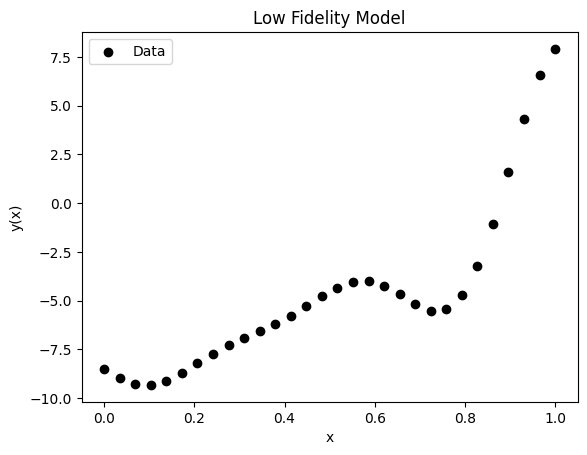

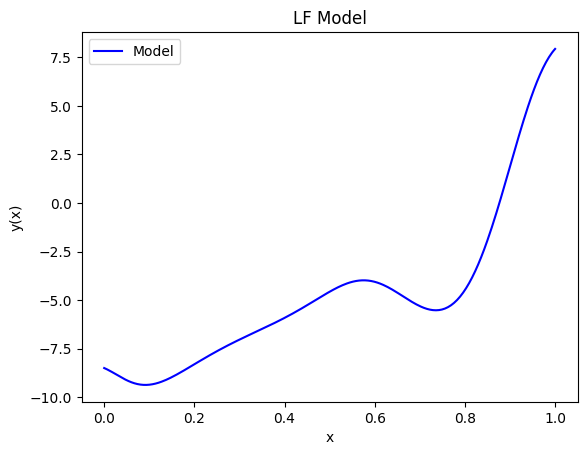

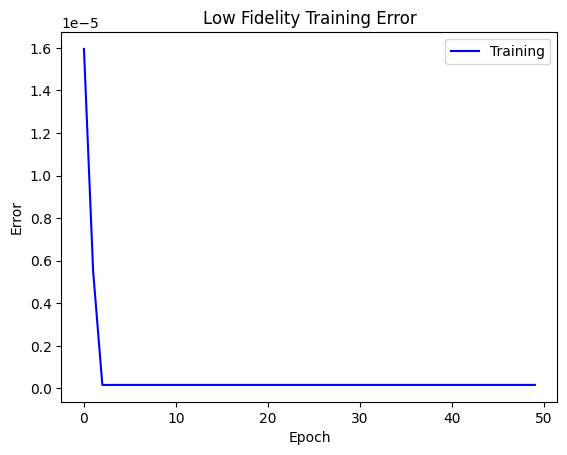

In [11]:
# Plot the results
lf_model.plot_data("Low Fidelity Model", label = "Data")
lf_model.plot_model(X_check,"LF Model", color = "blue", label="Model")
plt.show()

lf_model.plot_training_error("Low Fidelity Training Error")
plt.show()

## Multi-Fidelity Composite NN
Set-up a multi-fidelity NN and compare with test cases in Meng and Karniadakis 2020
### Smooth function fit

In [12]:
fxn_ind = 1
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)

lf_samp = 12
X_lf = np.zeros([lf_samp,1])
X_lf[:,0] = np.linspace(0.0,1.0,lf_samp,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = t.tensor(X_lf, dtype=t.float32)
y_lf = t.tensor(y_lf, dtype=t.float32)

hf_samp = 4
X_hf = np.zeros([hf_samp,1])
X_hf[:,0] = np.linspace(0.0,1.0,hf_samp,endpoint=True)
y_hf = hf_fxn.evaluate(X_hf)
X_hf = t.tensor(X_hf, dtype=t.float32)
y_hf = t.tensor(y_hf, dtype=t.float32)

mfnn_model = mfsnn.MultiFidelityNN(X_lf, y_lf, X_hf, y_hf, lf_nn_dim=[20,20], hf_linear_nn_dim=[10], hf_nl_nn_dim= [10,10],lr_lf=0.2,wd_lf=0.000001,lr_mf=0.1, wd_mf=0.01)

----Progress Update----
Epoch: 0 

Training Error: 0.008311598561704159 

----Progress Update----
Epoch: 1 

Training Error: 0.006402332801371813 

----Progress Update----
Epoch: 2 

Training Error: 0.006108753848820925 

----Progress Update----
Epoch: 3 

Training Error: 0.001871535088866949 

----Progress Update----
Epoch: 4 

Training Error: 0.0008160463185049593 

----Progress Update----
Epoch: 5 

Training Error: 0.00023316025908570737 

----Progress Update----
Epoch: 6 

Training Error: 0.0001052385414368473 

----Progress Update----
Epoch: 7 

Training Error: 6.972764094825834e-05 

----Progress Update----
Epoch: 8 

Training Error: 3.804470179602504e-05 

----Progress Update----
Epoch: 9 

Training Error: 2.6602492653182708e-05 

----Progress Update----
Epoch: 10 

Training Error: 1.7373255104757845e-05 

----Progress Update----
Epoch: 11 

Training Error: 1.261446323042037e-05 

----Progress Update----
Epoch: 12 

Training Error: 1.0924078196694609e-05 

----Progress Update---

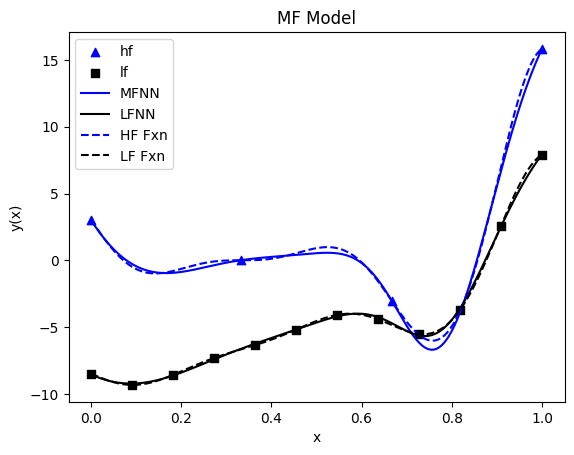

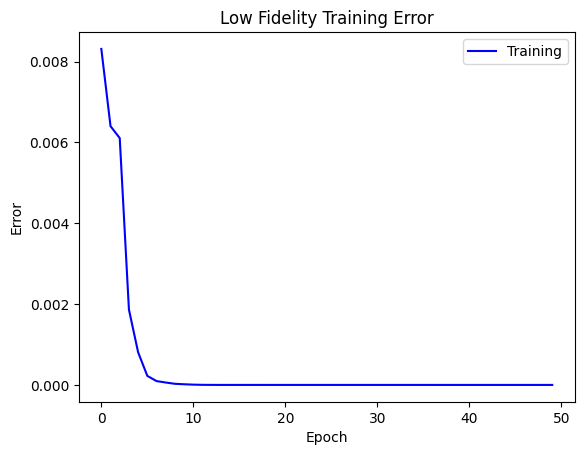

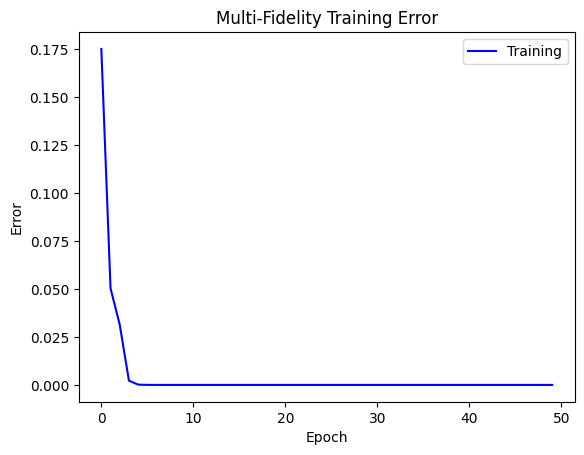

In [13]:
# Plot the results
mfnn_model.plot_data("MF Model")
X_check = np.zeros([300,1])
X_check[:,0] = np.linspace(0,1.0,300,endpoint=True)
X_check = t.tensor(X_check, dtype=t.float32)
mfnn_model.plot_model(X_check,"MF Model", color = "blue", label="MFNN")
mfnn_model.low_fidelity_nn.plot_model(X_check, name = "MF Model", label="LFNN")
hf_fxn.plot_data(name="MF Model",color = "blue", label="HF Fxn", linestyle="dashed")
lf_fxn.plot_data(name="MF Model",color = "black", label="LF Fxn", linestyle="dashed")
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.show()

In [19]:
fxn_ind = 6
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)

lf_samp = 38
X_lf = np.zeros([lf_samp,1])
X_lf[0:9,0] = np.linspace(0.0,0.4,9,endpoint=True)
X_lf[9:29,0] = np.linspace(0.4,0.6,20,endpoint=False)
X_lf[29:,0] = np.linspace(0.6,1.0,9,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)
X_lf = t.tensor(X_lf, dtype=t.float32)
y_lf = t.tensor(y_lf, dtype=t.float32)

hf_samp = 5
X_hf = np.zeros([hf_samp,1])
X_hf[:,0] = np.array([0.2,0.4,0.6,0.75,0.9])
y_hf = hf_fxn.evaluate(X_hf)
X_hf = t.tensor(X_hf, dtype=t.float32)
y_hf = t.tensor(y_hf, dtype=t.float32)

mfnn_model = mfsnn.MultiFidelityNN(X_lf, y_lf, X_hf, y_hf, lf_nn_dim=[20,20], hf_linear_nn_dim=[10], hf_nl_nn_dim= [10,10],lr_lf=0.01,wd_lf=0.000001,lr_mf=0.1, wd_mf=0.01)

----Progress Update----
Epoch: 0 

Training Error: 0.0009508314542472363 

----Progress Update----
Epoch: 1 

Training Error: 0.0006988816894590855 

----Progress Update----
Epoch: 2 

Training Error: 0.0004862670029979199 

----Progress Update----
Epoch: 3 

Training Error: 0.0010960669023916125 

----Progress Update----
Epoch: 4 

Training Error: 0.0013182880356907845 

----Progress Update----
Epoch: 5 

Training Error: 0.0004497333138715476 

----Progress Update----
Epoch: 6 

Training Error: 0.0014400637010112405 

----Progress Update----
Epoch: 7 

Training Error: 0.0013798348372802138 

----Progress Update----
Epoch: 8 

Training Error: 0.0014157528057694435 

----Progress Update----
Epoch: 9 

Training Error: 0.0023816865868866444 

----Progress Update----
Epoch: 10 

Training Error: 0.0016505541279911995 

----Progress Update----
Epoch: 11 

Training Error: 0.0011634352849796414 

----Progress Update----
Epoch: 12 

Training Error: 0.002119883894920349 

----Progress Update----

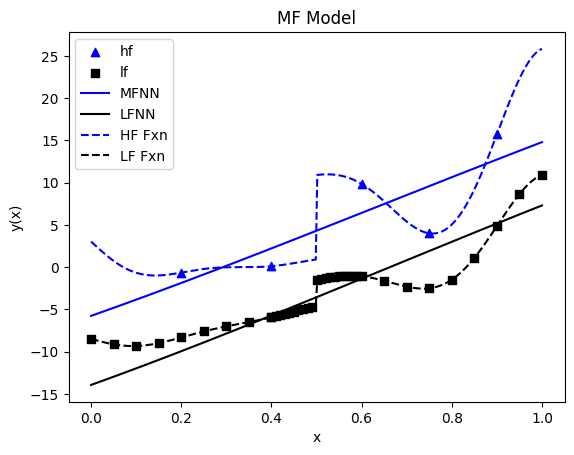

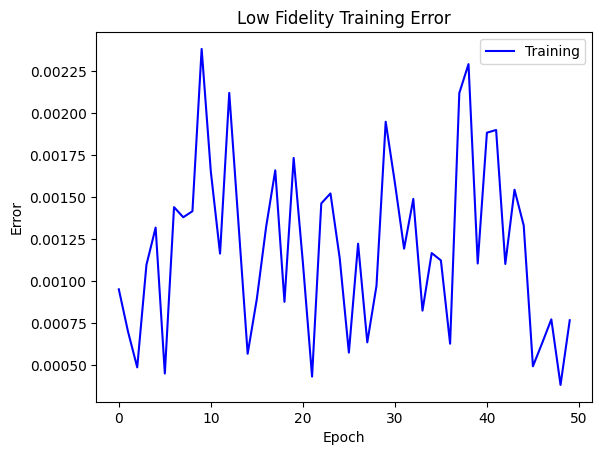

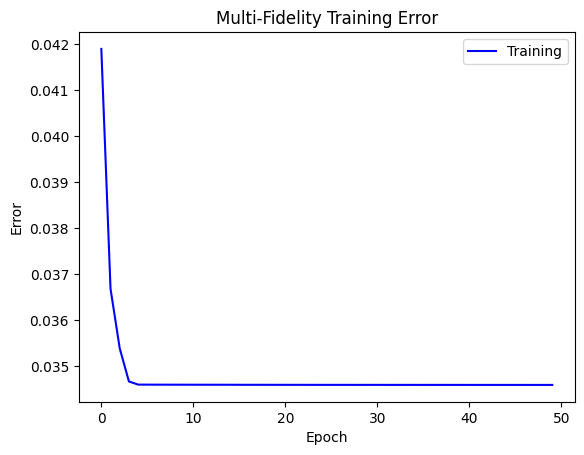

In [20]:
# Plot the results
mfnn_model.plot_data("MF Model")
X_check = np.zeros([300,1])
X_check[:,0] = np.linspace(0,1.0,300,endpoint=True)
X_check = t.tensor(X_check, dtype=t.float32)
mfnn_model.plot_model(X_check,"MF Model", color = "blue", label="MFNN")
mfnn_model.low_fidelity_nn.plot_model(X_check, name = "MF Model", label="LFNN")
hf_fxn.plot_data(name="MF Model",color = "blue", label="HF Fxn", linestyle="dashed")
lf_fxn.plot_data(name="MF Model",color = "black", label="LF Fxn", linestyle="dashed")
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.show()